# 03 - Pharmacodynamics and the PK/PD link

Pharmacokinetics (PK) asks *what the body does to the drug*. Pharmacodynamics (PD) asks
*what the drug does to the body*. Linking both tells us **how the effect evolves over time**.

**Goals**
1. The sigmoid Emax model: `E = E0 + Emax * C^n / (EC50^n + C^n)`
2. A direct PK/PD link: effect follows plasma concentration instantly
3. An **effect compartment** for delayed effects (hysteresis)
4. Compare dosing regimens using the *time above EC50*

> The drug below ("Drug X") and its PD parameters are **hypothetical**, chosen for teaching.

In [2]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pkpd import models as m

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. The sigmoid Emax model

- `Emax`: maximal effect
- `EC50`: concentration giving 50% of `Emax` (potency)
- `n` (Hill coefficient): steepness of the curve

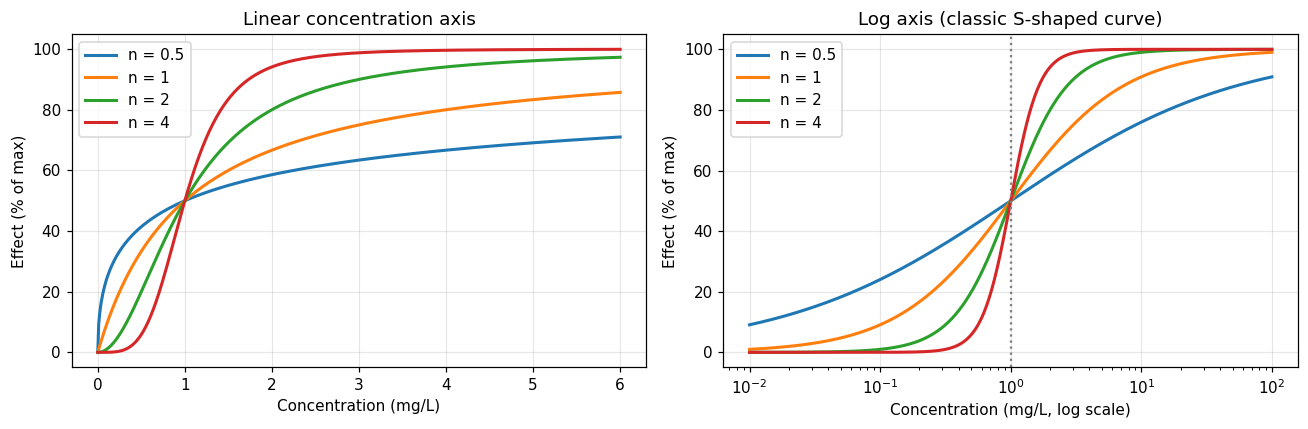

In [3]:
Emax, EC50 = 100.0, 1.0           # effect in % of maximum, EC50 in mg/L
conc = np.linspace(0, 6, 600)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for n in (0.5, 1, 2, 4):
    e = m.emax_model(conc, Emax, EC50, n)
    axes[0].plot(conc, e, lw=2, label=f"n = {n}")
axes[0].set_title("Linear concentration axis")
axes[0].set_xlabel("Concentration (mg/L)"); axes[0].set_ylabel("Effect (% of max)")
axes[0].legend()

conc_log = np.logspace(-2, 2, 600)
for n in (0.5, 1, 2, 4):
    axes[1].semilogx(conc_log, m.emax_model(conc_log, Emax, EC50, n), lw=2, label=f"n = {n}")
axes[1].axvline(EC50, ls=":", c="gray")
axes[1].set_title("Log axis (classic S-shaped curve)")
axes[1].set_xlabel("Concentration (mg/L, log scale)"); axes[1].set_ylabel("Effect (% of max)")
axes[1].legend()
plt.tight_layout(); plt.show()

A steeper curve (larger `n`) means a narrower concentration range between a weak and a
near-maximal effect. The table shows the EC10, EC50 and EC90 for each Hill coefficient.

In [4]:
rows = []
for n in (0.5, 1, 2, 4):
    rows.append({
        "Hill n": n,
        "EC10 (mg/L)": m.ec_fraction(EC50, n, 0.1),
        "EC50 (mg/L)": m.ec_fraction(EC50, n, 0.5),
        "EC90 (mg/L)": m.ec_fraction(EC50, n, 0.9),
        "EC90 / EC10": m.ec_fraction(EC50, n, 0.9) / m.ec_fraction(EC50, n, 0.1),
    })
pd.DataFrame(rows).set_index("Hill n").round(3)

,EC10 (mg/L),EC50 (mg/L),EC90 (mg/L),EC90 / EC10
Hill n,,,,
0.5,0.012,1.0,81.000,6561.0
1.0,0.111,1.0,9.000,81.0
2.0,0.333,1.0,3.000,9.0
4.0,0.577,1.0,1.732,3.0


## 2. Direct PK/PD link

"Drug X": one-compartment, `V = 50 L`, `CL = 10 L/h`. We give 100 mg IV and assume the
effect follows the plasma concentration instantly, with `EC50 = 1 mg/L` and `n = 1.5`.

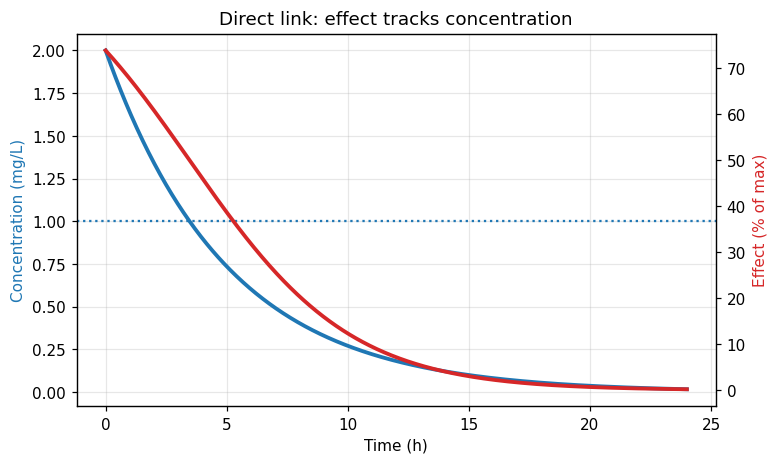

Time with C > EC50: 3.45 h  (analytical: 3.47 h)


In [5]:
V, CL = 50.0, 10.0
k = CL / V
hill = 1.5
dose_iv = 100.0

t = np.linspace(0, 24, 800)
cp = m.one_comp_iv(t, dose_iv, V, k)
e_direct = m.emax_model(cp, Emax, EC50, hill)

fig, ax1 = plt.subplots(figsize=(7.5, 4.4))
ax1.plot(t, cp, c="tab:blue", lw=2.5, label="Plasma concentration")
ax1.axhline(EC50, ls=":", c="tab:blue")
ax1.set_xlabel("Time (h)"); ax1.set_ylabel("Concentration (mg/L)", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(t, e_direct, c="tab:red", lw=2.5, label="Effect")
ax2.set_ylabel("Effect (% of max)", color="tab:red"); ax2.grid(False)
ax1.set_title("Direct link: effect tracks concentration")
plt.show()

t_above = t[cp > EC50].max()
print(f"Time with C > EC50: {t_above:.2f} h  (analytical: {np.log((dose_iv / V) / EC50) / k:.2f} h)")

## 3. Effect compartment and hysteresis

Many drugs need time to reach the site of action. An **effect compartment** adds a delay:
`dCe/dt = ke0 * (Cp - Ce)`, and the effect is driven by `Ce`, not `Cp`.
A smaller `ke0` means a longer delay.

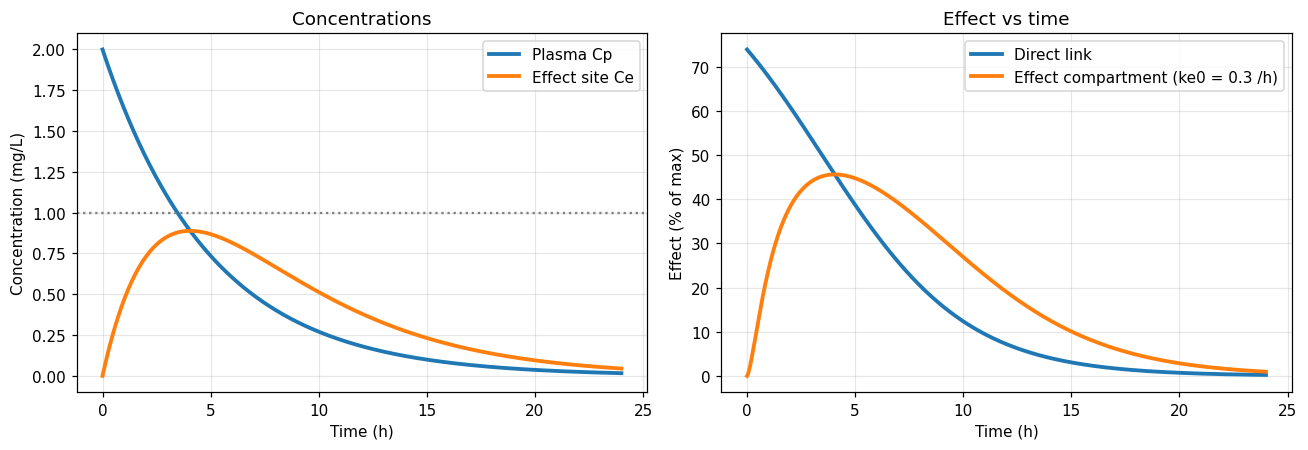

Peak of Ce at 4.06 h (theory: 4.05 h)
Peak delayed effect: 45.6% at 4.06 h


In [6]:
ke0 = 0.3
ce = m.effect_site_concentration(t, dose_iv, V, k, ke0)
e_delayed = m.emax_model(ce, Emax, EC50, hill)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(t, cp, lw=2.5, label="Plasma Cp")
axes[0].plot(t, ce, lw=2.5, label="Effect site Ce")
axes[0].axhline(EC50, ls=":", c="gray")
axes[0].set_xlabel("Time (h)"); axes[0].set_ylabel("Concentration (mg/L)")
axes[0].set_title("Concentrations"); axes[0].legend()

axes[1].plot(t, e_direct, lw=2.5, label="Direct link")
axes[1].plot(t, e_delayed, lw=2.5, label=f"Effect compartment (ke0 = {ke0} /h)")
axes[1].set_xlabel("Time (h)"); axes[1].set_ylabel("Effect (% of max)")
axes[1].set_title("Effect vs time"); axes[1].legend()
plt.tight_layout(); plt.show()

print(f"Peak of Ce at {t[np.argmax(ce)]:.2f} h (theory: {np.log(ke0 / k) / (ke0 - k):.2f} h)")
print(f"Peak delayed effect: {e_delayed.max():.1f}% at {t[np.argmax(e_delayed)]:.2f} h")

### Hysteresis loop
Plotting effect against **plasma** concentration reveals the delay: with a direct link the
points lie on a single curve, with an effect compartment they form a loop
(the effect is lower than expected while the concentration is high, then higher on the way down).

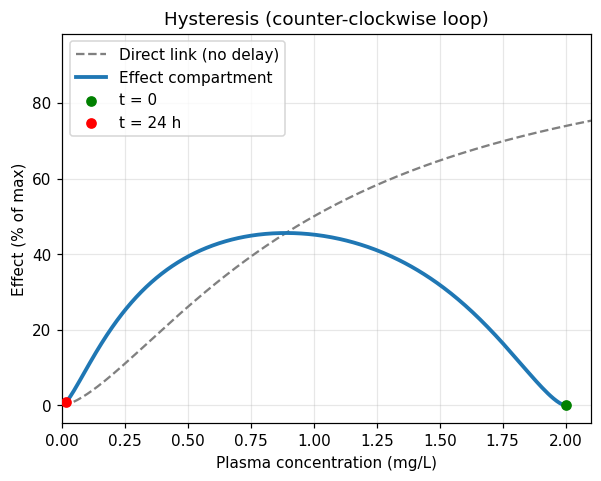

In [7]:
plt.figure(figsize=(6.2, 4.6))
plt.plot(conc, m.emax_model(conc, Emax, EC50, hill), "--", c="gray", label="Direct link (no delay)")
plt.plot(cp, e_delayed, lw=2.5, label="Effect compartment")
plt.scatter([cp[0]], [e_delayed[0]], c="green", zorder=5, label="t = 0")
plt.scatter([cp[-1]], [e_delayed[-1]], c="red", zorder=5, label="t = 24 h")
plt.xlim(0, 2.1)
plt.xlabel("Plasma concentration (mg/L)"); plt.ylabel("Effect (% of max)")
plt.title("Hysteresis (counter-clockwise loop)")
plt.legend(); plt.show()

## 4. Comparing regimens: same daily dose, different effect

Drug X is now given **orally** (`F = 0.8`, `ka = 1.2 /h`). Both regimens deliver 300 mg per day:

- **A**: 100 mg every 8 h
- **B**: 200 mg every 16 h (the dose is larger but less frequent)

The average concentration is identical, but is the effect?

In [8]:
F, ka = 0.8, 1.2

def simulate(dose, tau, days=4):
    n = int(days * 24 / tau)
    t_all = np.linspace(0, n * tau, 4000)
    cp_all = m.multiple_dose(m.one_comp_oral, t_all, tau, n, dose=dose, V=V, k=k, ka=ka, F=F)
    # last dosing interval (approximate steady state)
    t_ss = np.linspace((n - 1) * tau, n * tau, 4000)
    cp_ss = m.multiple_dose(m.one_comp_oral, t_ss, tau, n, dose=dose, V=V, k=k, ka=ka, F=F)
    e_ss = m.emax_model(cp_ss, Emax, EC50, hill)
    summary = {
        "Dose (mg)": dose,
        "Interval (h)": tau,
        "Css,avg (mg/L)": m.css_average(dose, CL, tau, F),
        "Cmax,ss (mg/L)": cp_ss.max(),
        "Cmin,ss (mg/L)": cp_ss.min(),
        "% time > EC50": 100 * m.fraction_time_above(cp_ss, EC50),
        "Mean effect (%)": e_ss.mean(),
    }
    return t_all, cp_all, summary

tA, cA, sA = simulate(100, 8)
tB, cB, sB = simulate(200, 16)

pd.DataFrame({"A: 100 mg q8h": sA, "B: 200 mg q16h": sB}).round(2)

,A: 100 mg q8h,B: 200 mg q16h
Dose (mg),100.00,200.00
Interval (h),8.00,16.00
"Css,avg (mg/L)",1.00,1.00
"Cmax,ss (mg/L)",1.47,2.35
"Cmin,ss (mg/L)",0.49,0.16
% time > EC50,49.60,41.68
Mean effect (%),48.11,42.02


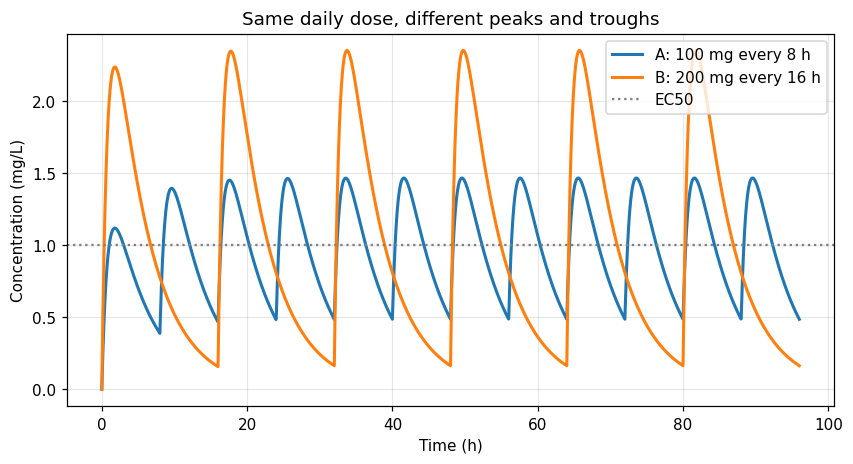

In [9]:
plt.figure(figsize=(9, 4.4))
plt.plot(tA, cA, lw=2, label="A: 100 mg every 8 h")
plt.plot(tB, cB, lw=2, label="B: 200 mg every 16 h")
plt.axhline(EC50, ls=":", c="gray", label="EC50")
plt.xlabel("Time (h)"); plt.ylabel("Concentration (mg/L)")
plt.title("Same daily dose, different peaks and troughs")
plt.legend(); plt.show()

## Takeaways
- The **Hill coefficient** controls how steep the concentration-effect relationship is.
- `EC50` is a measure of potency; the **time above EC50** is a simple way to compare regimens.
- With a delay between plasma and effect, an **effect compartment** (`ke0`) explains hysteresis.
- Two regimens with the same average concentration can differ in effect, because the
  response is non-linear in concentration.

**Next:** an interactive Streamlit app to explore all these parameters with sliders.